# PRABHKIRAT SINGH MARWAH 
# SECTION: B
# BATCH: B4
# ROLL NO: 47 
# ML LAB 7  NAIVE BAYES CLASSIFICATION 

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay)
pd.set_option('display.max_columns', None)

In [3]:
df = pd.read_csv("Raisin_Dataset.csv")
df.head()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
0,87524,442.246011,253.291155,0.819738,90546,0.758651,1184.040,Kecimen
1,75166,406.690687,243.032436,0.801805,78789,0.684130,1121.786,Kecimen
2,90856,442.267048,266.328318,0.798354,93717,0.637613,1208.575,Kecimen
3,45928,286.540559,208.760042,0.684989,47336,0.699599,844.162,Kecimen
4,79408,352.190770,290.827533,0.564011,81463,0.792772,1073.251,Kecimen


In [7]:
df.tail()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
895,83248,430.077308,247.838695,0.817263,85839,0.668793,1129.072,Besni
896,87350,440.735698,259.293149,0.808629,90899,0.636476,1214.252,Besni
897,99657,431.706981,298.837323,0.721684,106264,0.741099,1292.828,Besni
898,93523,476.344094,254.176054,0.845739,97653,0.658798,1258.548,Besni
899,85609,512.081774,215.271976,0.907345,89197,0.632020,1272.862,Besni


In [8]:
label_encoder = LabelEncoder()
df['Class_encoded'] = label_encoder.fit_transform(df['Class'])
print(df[["Class","Class_encoded"]].head(5))

     Class  Class_encoded
0  Kecimen              1
1  Kecimen              1
2  Kecimen              1
3  Kecimen              1
4  Kecimen              1


In [9]:
numerical_features = df.select_dtypes(include=np.number).columns

In [10]:
X = df[numerical_features]
y =df["Class_encoded"]

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)
print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])


Training Samples: 720
Testing Samples: 180


In [12]:
GaussianNB()

GaussianNB()

In [13]:
gnb = GaussianNB()
gnb .fit(X_train,y_train)

GaussianNB()

In [14]:
y_pred = gnb.predict(X_test)
print("Predicted labels:")
print(y_pred)

Predicted labels:
[1 0 0 1 0 1 0 1 1 1 1 1 1 1 0 1 1 1 0 0 0 1 1 1 1 1 1 1 1 1 1 1 0 0 1 0 1
 0 0 0 0 0 0 0 0 0 0 1 0 0 1 1 0 1 1 1 0 1 0 0 0 1 1 0 0 1 0 1 1 1 1 0 0 1
 1 1 0 1 0 1 0 1 1 1 1 0 1 1 1 1 0 1 1 0 1 1 1 1 1 0 1 1 1 0 1 0 1 0 1 1 0
 1 1 0 1 0 1 0 0 1 0 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 0 1 1 1 0 1 1 0 0 1
 1 1 1 0 0 1 1 1 0 1 1 0 1 0 0 0 0 1 1 1 1 1 1 0 1 1 1 0 0 1 0 1]


In [15]:
comparison = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})
print(comparison.head(5))

     Actual  Predicted
502       0          1
637       0          0
701       0          0
237       1          1
707       0          0


In [16]:
comparison["Actual_Class"]=label_encoder.inverse_transform(comparison["Actual"])
comparison["Predicted_Class"]=label_encoder.inverse_transform(comparison["Predicted"])
print(comparison.head(5))

     Actual  Predicted Actual_Class Predicted_Class
502       0          1        Besni         Kecimen
637       0          0        Besni           Besni
701       0          0        Besni           Besni
237       1          1      Kecimen         Kecimen
707       0          0        Besni           Besni


In [17]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)
print("Accuracy (%):", accuracy * 100)

Accuracy: 0.8277777777777777
Accuracy (%): 82.77777777777777


In [18]:
precision = precision_score(y_test, y_pred, average='weighted')
print("Precision:", precision)

Precision: 0.8466509988249119


In [19]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)
print("Accuracy (%):", accuracy * 100)

Accuracy: 0.8277777777777777
Accuracy (%): 82.77777777777777


In [20]:
precision = precision_score(y_test, y_pred, average='weighted')
print("Precision:", precision)

Precision: 0.8466509988249119


In [21]:
recall = recall_score(y_test, y_pred, average='weighted')
print("Recall:", recall)

Recall: 0.8277777777777777


In [22]:
f1 = f1_score(y_test, y_pred, average='weighted')
print("F1 Score:", f1)

F1 Score: 0.8254012954097438


In [23]:
print("==== MODEL PERFORMANCE EVALUATION ====")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

==== MODEL PERFORMANCE EVALUATION ====
Accuracy: 0.8277777777777777
Precision: 0.8466509988249119
Recall: 0.8277777777777777
F1 Score: 0.8254012954097438


In [24]:
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))

Classification Report:
              precision    recall  f1-score   support

       Besni       0.93      0.71      0.81        90
     Kecimen       0.77      0.94      0.85        90

    accuracy                           0.83       180
   macro avg       0.85      0.83      0.83       180
weighted avg       0.85      0.83      0.83       180



In [25]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[64 26]
 [ 5 85]]


Text(58.222222222222214, 0.5, 'Actual')

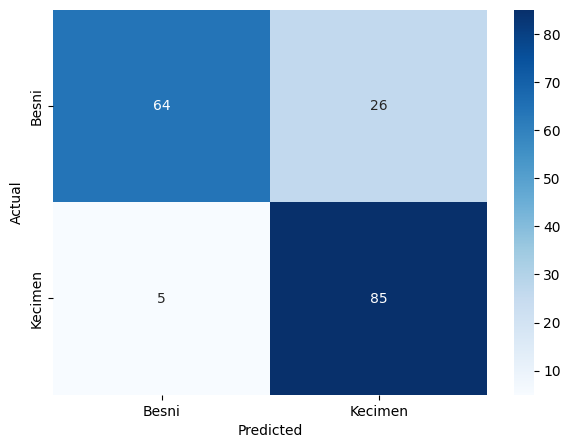

In [26]:
plt.figure(figsize=(7,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')

In [27]:
from sklearn.metrics import accuracy_score
y_train_pred = gnb.predict(X_train)
y_test_pred = gnb.predict(X_test)
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)
print("Training Accuracy:", train_accuracy)
print("Testing Accuracy:", test_accuracy)

Training Accuracy: 0.8375
Testing Accuracy: 0.8277777777777777


In [28]:
GaussianNB(priors=None)

GaussianNB()